# DSA 107 — Lab 4: Getting data from the wild

**Week 4 · w/c 19 October 2026** · paired with DSA 101 lecture week 4

**Name:** Andrei Tiniakov   **Student ID:** 26022121102

---

### What you will produce

A runnable Colab notebook, pushed to your `dsa107-labs` repository. In it you ask a web service for data, turn its JSON answer into a table, repair the columns, summarise the table and draw one labelled figure from it, and read a table straight off a web page.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install requests pandas matplotlib seaborn lxml` in a new cell and try again.

This lab talks to **real services over the internet**. If one of them does not answer, print the status code first and tell your instructor — do not keep sending the same request.

### How to use this notebook

Every code cell has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The table below shows how they add up to the 10 code points.

A code cell only shows the result of its **last line**. If you want to see two or more things from one cell, put each of them inside `print()`.

The **Command reference** below holds the commands you need for this lab, and a few more besides. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| Asking the API | Goals 1a, 1b (0.5 each) | 1 |
| From JSON to a table | Goals 2a, 2b (0.75 each) | 1.5 |
| Cleaning | Goal 3a | 1 |
| Group summary | Goal 4a | 1 |
| Figure | Goal 4b (needs an x label, a y label and a title) | 1 |
| Reading a table from a web page | Goals 5a, 5b (0.75 each) | 1.5 |
| Interpretation | Q1, Q2, Q3, Q4 (0.75 each) | 3 |
| **Total** | | **10** |

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__)

pandas 3.0.6


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series).
Not every command here is needed for this lab — choosing the right one is part of the work.

**Asking a server for data — new this week**

| Command | What it does |
| --- | --- |
| `requests.get(url)` | asks the server at `url` for data, and hands you back a **response** |
| `requests.get(url, headers=headers)` | the same, but also tells the server who you are |
| `requests.get(url, params={"page": 2})` | the same, but adds `?page=2` to the address for you |
| `response.status_code` | `200` it worked · `403` not allowed · `404` wrong address · `429` too many requests |
| `response.json()` | turns a JSON answer into ordinary Python lists and dictionaries |
| `response.text` | gives you the answer as plain text (use this for a web page) |

**Looking at a JSON answer — new this week**

JSON is built from two things. `{ }` is a **dictionary**: named fields, like one row. `[ ]` is a **list**: repeated things, like rows. They sit inside each other, to any depth.

| Command | What it does |
| --- | --- |
| `type(x)` | tells you what `x` is: `list`, `dict`, `str`, `int` … |
| `len(x)` | how many items a list has, or how many fields a dictionary has |
| `x.keys()` | the names of the fields of a dictionary |
| `x[0]` | the **first** item of a list — Python counts from 0 |
| `x["name"]` | the field called `name` of a dictionary |
| `x[1][0]` | the first item of the second item — you can chain them |

**From a JSON tree to a table — new this week**

| Command | What it does |
| --- | --- |
| `pd.DataFrame(records)` | builds a table from a list of **flat** dictionaries |
| `pd.json_normalize(records)` | the same, but also opens up nested dictionaries: a field `region` holding `{"value": "X"}` becomes a column named `region.value` |

**Looking at the table**

| Command | What it does |
| --- | --- |
| `df.head(n)` | returns the first `n` rows (5 if you do not say) |
| `df.tail(n)` | returns the **last** `n` rows |
| `df.shape` | gives (number of rows, number of columns) |
| `len(df)` | gives the number of rows |
| `df.info()` | prints the column names, their types and their non-missing counts |
| `df.isna().sum()` | gives the number of missing values in each column |
| `s.value_counts()` | counts how many times each value appears |
| `s.sort_values(ascending=False)` | sorts from largest to smallest |

**Choosing, renaming and repairing columns — new this week**

| Command | What it does |
| --- | --- |
| `df[["a", "b"]]` | keeps only these columns — note the **double** brackets |
| `df.rename(columns={"old": "new"})` | gives a column a new name |
| `df.dtypes` | what each column is stored as: `object` = text, `int64` / `float64` = numbers |
| `pd.to_numeric(s)` | turns a text column into real numbers |
| `pd.to_numeric(s, errors="coerce")` | the same, but anything that is not a number becomes `NaN` (missing) instead of an error |
| `df["col"] = ...` | puts a column back into the table, replacing the old one |

**Choosing rows — from last week**

| Command | What it does |
| --- | --- |
| `df["col"] == "x"` | a **boolean mask**: for every row, is the value equal to `"x"`? |
| `df["col"] != "x"` | for every row: is the value **not** equal to `"x"`? |
| `df[mask]` | keeps only the rows where the mask is `True` |
| `mask.sum()` | how many rows are `True` |

**Group summaries — from last week**

| Command | What it does |
| --- | --- |
| `df.groupby("g")["x"].count()` | how many rows there are in each group |
| `.mean()` `.median()` `.max()` `.min()` | put one of these in place of `.count()` for another summary |
| `df.groupby(["g1", "g2"])["x"].count()` | one group for every **combination** of `g1` and `g2` |
| `.unstack()` | turns a two-key result into a grid: `g1` down the side, `g2` across the top |
| `grid.sum(axis=1)` | adds up each **row** of a grid and gives one number per row |

**Reading tables off a web page — new this week**

| Command | What it does |
| --- | --- |
| `pd.read_html(StringIO(page.text))` | finds **every** `<table>` on the page and gives you a **list** of DataFrames |
| `len(tables)` | how many tables it found |
| `tables[3]` | picks table number 3 out of the list |
| `t.shape` and `list(t.columns)` | use these on each table to find the one you want |

**Drawing and labelling**

The plot commands hand you back an *axes* object. Catch it in a variable (`ax = ...`) and you can label it.

| Command | What it does |
| --- | --- |
| `plt.figure(figsize=(10, 5))` | makes the **next** figure 10 wide and 5 tall |
| `ax = s.plot.bar()` | draws a bar chart, one bar per row |
| `ax = df.plot.scatter(x="a", y="b")` | draws a scatter plot: one dot per row |
| `ax = sns.scatterplot(data=df, x="a", y="b", hue="g")` | a scatter plot with the dots **coloured** by the groups in `g` |
| `ax.set_xlabel("...")` | names the horizontal axis |
| `ax.set_ylabel("...")` | names the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `ax.legend(title="...", bbox_to_anchor=(1.02, 1), loc="upper left")` | moves the legend **outside** the figure, so it does not cover the dots |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. Ask a server for data

In the first three weeks the data was a CSV file waiting at a web address, and `read_csv` loaded it. This week you **ask** for the data instead.

An **API** is a service you can talk to over the internet. You send a request; it sends an answer back. The answer is usually **JSON**, not a table.

This week's service is the **World Bank country API**. For every country in the world it knows which region it is in, which income group the World Bank puts it in, what its capital city is, and where that capital sits on the map.

Two habits start here, and you will keep them for the rest of the course:

- **Check the status code.** `200` means the server understood you and answered. Any other number means stop and look at what you got.
- **Look at the answer before you turn it into a table.** A DataFrame is flat; JSON is a tree. You cannot choose which branch becomes your rows until you have seen the tree.

> **Goal 1a · 0.5 pt.** Send the request (the address is already written for you). Print the **status code**, then turn the answer into Python with `.json()`, store it as `data`, and print `type(data)`.

In [4]:
url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

# TODO: send the request and store the answer as response
# TODO: print the status code
# TODO: turn the answer into Python (call it data) and print its type

response = requests.get(url)
print(response.status_code)
data = response.json()
print(type(data))


200
<class 'list'>


> **Goal 1b · 0.5 pt.** Look at the answer before you turn it into a table. Print how many parts `data` has, then print the **first part** on its own. Then print how many records are in the **second part**, and show the **first record** of it.
> The first record is a dictionary. Read its field names — those will become your columns.

In [11]:
# TODO: print how many parts data has
# TODO: print the first part (data[0])
# TODO: print how many records are in the second part (data[1])
# TODO: show the first record of the second part
print(len(data))
print(data[0])
print(len(data[1]))
print(data[1][0])

2
{'page': 1, 'pages': 1, 'per_page': '400', 'total': 296}
296
{'id': 'ABW', 'iso2Code': 'AW', 'name': 'Aruba', 'region': {'id': 'LCN', 'iso2code': 'ZJ', 'value': 'Latin America & Caribbean '}, 'adminregion': {'id': '', 'iso2code': '', 'value': ''}, 'incomeLevel': {'id': 'HIC', 'iso2code': 'XD', 'value': 'High income'}, 'lendingType': {'id': 'LNX', 'iso2code': 'XX', 'value': 'Not classified'}, 'capitalCity': 'Oranjestad', 'longitude': '-70.0167', 'latitude': '12.5167'}


**Q1 · 0.75 pt.**
(a) What status code did the server send back, and what does that number mean?
(b) The answer has two parts. What is in the first part, and what is in the second part?
(c) How many records did the server say there are in total, and how many did you actually get? Are those two numbers the same, and why?

*Write your answer here.*
a) It sends statu 200: OK. It means that the server handled the request successfully and we can use the result in the body
b) It's a basic pagination wrapper response - first part has metadata related to the page like what page number it is, how many items we get per page and how many items there are in total. Second part is the content itself, which has promised 296 items.
c) Server said there are 296 items in total, and since we set the page size to 400, as expected, we got 296 items since there are less items on the server then the page size we asked for. if there were more then 400 items in total we would get 400 since page size is 400.

## 2. From a JSON tree to a table

`pd.DataFrame()` works when the records are a **flat** list of dictionaries. These records are not flat: the field `region` is itself a small dictionary, with `id`, `iso2code` and `value` inside it.

`pd.json_normalize()` deals with that. It walks into the nested dictionaries and makes one column for every leaf, joining the names with a dot — the `value` inside `region` becomes a column called **`region.value`**.

What you get back is a wide table with names you did not choose. So the next step is always the same: **keep the columns you need, and give them names you can type.**

> **Goal 2a · 0.75 pt.** Build a DataFrame called `countries_raw` from the **records** (the second part of `data`) with `pd.json_normalize`. Print its shape, then show the first five rows.

In [13]:
# TODO: build countries_raw from the records with json_normalize
# TODO: print its shape, then show the first five rows

countries_raw = pd.json_normalize(data[1])
print(countries_raw.shape)
countries_raw.head()

(296, 18)


,id,iso2Code,name,capitalCity,longitude,latitude,region.id,region.iso2code,region.value,adminregion.id,adminregion.iso2code,adminregion.value,incomeLevel.id,incomeLevel.iso2code,incomeLevel.value,lendingType.id,lendingType.iso2code,lendingType.value
0,ABW,AW,Aruba,Oranjestad,-70.0167,12.5167,LCN,ZJ,Latin America & Caribbean,,,,HIC,XD,High income,LNX,XX,Not classified
1,AFE,ZH,Africa Eastern and Southern,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates
2,AFG,AF,Afghanistan,Kabul,69.1761,34.5228,MEA,ZQ,"Middle East, North Africa, Afghanistan & Pakistan",MNA,XQ,"Middle East, North Africa, Afghanistan & Pakis...",LIC,XM,Low income,IDX,XI,IDA
3,AFR,A9,Africa,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates
4,AFW,ZI,Africa Western and Central,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates


> **Goal 2b · 0.75 pt.** Keep only the seven columns listed below and store the result as `countries`. Then **rename** the two columns that have a dot in their name: `region.value` → `region` and `incomeLevel.value` → `income_level`.
> Now print `countries.dtypes` and look at `longitude` and `latitude`. Turn both of them into real numbers with `pd.to_numeric(..., errors="coerce")`, put them back into the table, and print `countries.dtypes` again.

In [24]:
keep = ["id", "name", "capitalCity", "longitude", "latitude", "region.value", "incomeLevel.value"]

# TODO: keep those columns and rename the two with a dot in their name; call the result countries
countries = countries_raw[keep].rename(columns={
    "region.value": "region",
    "incomeLevel.value": "income_level",
})
# TODO: print the dtypes BEFORE you change anything
print(countries.dtypes)

# TODO: turn longitude and latitude into numbers with errors="coerce"
countries["longitude"] = pd.to_numeric(countries["longitude"], errors="coerce")
countries["latitude"] = pd.to_numeric(countries["latitude"], errors="coerce")

# TODO: print the dtypes AFTER
print(countries.dtypes)

id              str
name            str
capitalCity     str
longitude       str
latitude        str
region          str
income_level    str
dtype: object
id                  str
name                str
capitalCity         str
longitude       float64
latitude        float64
region              str
income_level        str
dtype: object


**Q2 · 0.75 pt.**
(a) How many rows and how many columns did `json_normalize` give you, and what does one row stand for?
(b) Look at the dtypes you printed **before** the change. What were `longitude` and `latitude` stored as? Why would that be a problem if you wanted to draw them on a figure?

*Write your answer here.*
a) json normalize gave me 18 columns and 296 rows. One row means one country or an aggregate of them.
b) Before those 2 columns were of type string which doesn't make sense for longitude and latitude which is why we convert it to float. If we wanted to draw a figure with those 2 as strings we would consider it a ENUM which is wrong - we need to make it quantitative.

## 3. Not every row is a country

The list has 296 rows, but there are not 296 countries in the world. Along with the countries, the World Bank list holds **aggregates**: rows such as *Africa Eastern and Southern*, *Euro area* or *World*, which are **groups** of countries rather than countries.

Every aggregate has the word `Aggregates` in its `region` column.

If you leave them in, you will count them as countries and every answer after this point will be wrong. Last week's **boolean mask** is exactly the right tool.

> **Goal 3a · 1 pt.** Print how many rows `countries` has now. Then keep only the rows whose `region` is **not** `"Aggregates"`, store the result back in `countries`, and print how many rows are left. Finally, print how many values are missing in each column.

In [31]:
# TODO: print the number of rows before
# TODO: keep only the rows that are real countries
# TODO: print the number of rows after
# TODO: print how many values are missing in each column
print(len(countries))

mask = countries["region"] != "Aggregates"
print(mask.sum())
countries = countries[mask]

print(countries.isna().sum())


296
217
id              0
name            0
capitalCity     0
longitude       6
latitude        6
region          0
income_level    0
dtype: int64


## 4. Summarise it, and draw it

The data is yours now, so the rest is last week's work: **split, apply, combine**, and one labelled figure.

The figure is a scatter plot of `longitude` against `latitude`. That is only two numbers per capital city. But if you draw two hundred of them at once, you will see something familiar.

> **Goal 4a · 1 pt.** Count how many countries there are for every combination of `region` and `income_level`. Use `.unstack()` so that `region` runs down the side and `income_level` runs across the top. Store it as `by_two` and show it.
> An empty cell shows `NaN`. It means there is no country in that combination.

In [39]:
# TODO: count the countries for every region and income_level combination, as a grid, stored as by_two
by_two = countries.groupby(["region", "income_level"]).size().unstack()
print(by_two)



income_level                                       High income  Low income  Lower middle income  Upper middle income
region                                                                                                              
East Asia & Pacific                                       15.0         1.0                  8.0                 13.0
Europe & Central Asia                                     40.0         NaN                  3.0                 15.0
Latin America & Caribbean                                 19.0         NaN                  5.0                 18.0
Middle East, North Africa, Afghanistan & Pakistan          8.0         3.0                  7.0                  5.0
North America                                              3.0         NaN                  NaN                  NaN
South Asia                                                 NaN         NaN                  4.0                  2.0
Sub-Saharan Africa                                         1.0  

> **Goal 4b · Figure · 1 pt.** Draw a scatter plot with `longitude` on the x-axis and `latitude` on the y-axis, with the dots **coloured by `region`**. Give it an x label, a y label and a title, and move the legend outside the figure so that it does not cover the dots (there is a line for that in the Command reference).

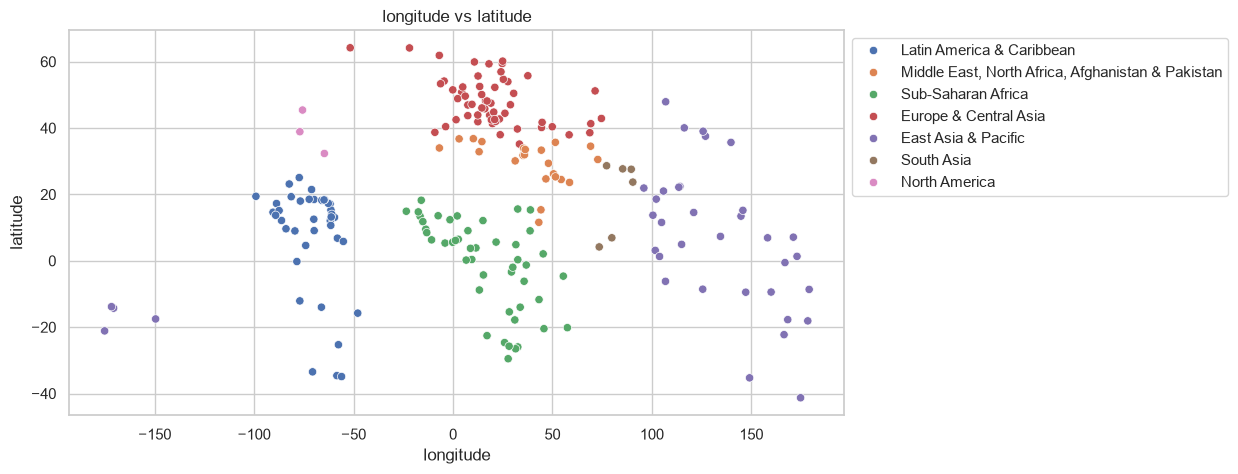

In [58]:
plt.figure(figsize=(10, 5))

# TODO: scatter plot of longitude (x) against latitude (y), coloured by region
ax = sns.scatterplot(data=countries, x="longitude", y="latitude", hue="region")

# TODO: x label, y label, title, and move the legend outside
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("longitude vs latitude")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.show()

**Q3 · 0.75 pt.**
(a) Add up each row of `by_two` (an empty `NaN` cell adds nothing). Which region has the most countries in total, and which has the fewest? Give both numbers.
(b) Find one `NaN` in `by_two` and name the combination it belongs to. What does `NaN` mean here — zero countries, or something else?
(c) Look at your figure. Name one thing the picture tells you that the `by_two` grid cannot.

*Write your answer here.*

a)
region
East Asia & Pacific                                  37.0
Europe & Central Asia                                58.0
Latin America & Caribbean                            42.0
Middle East, North Africa, Afghanistan & Pakistan    23.0
North America                                         3.0
South Asia                                            6.0
Sub-Saharan Africa                                   48.0

Region with most counties: Europe & Central Asia (58)
Region with least counties: North America (3)

b) High income + South Asia gives NaN - it means there are no countries with region South Asia that has High income

c) The figure shows us the geographic location and how countries are distributed across different regions


In [57]:
print(by_two.sum(axis="columns"))

region
East Asia & Pacific                                  37.0
Europe & Central Asia                                58.0
Latin America & Caribbean                            42.0
Middle East, North Africa, Afghanistan & Pakistan    23.0
North America                                         3.0
South Asia                                            6.0
Sub-Saharan Africa                                   48.0
dtype: float64


## 5. A table that is already sitting on a web page

Not everything has an API. Very often the numbers you want are already in a table on a web page, drawn for human eyes rather than for your code.

A web page is a tree as well, written in HTML: a `<table>` holds `<tr>` rows, which hold `<td>` cells. `pd.read_html` walks that tree for you and turns **every** table on the page into a DataFrame.

Two warnings before you start:

- It hands you a **list**, not a table. A page can hold a dozen tables, and most of them are menus and boxes you do not want. Print the shape of each one and find yours. Never guess the number.
- What comes back is **dirty**. Numbers often arrive as text, and footnote markers stick to values. Cleaning that is next week's lecture. Today you only have to notice it.

(`read_html` only finds real `<table>` tags. When a page has none, you need BeautifulSoup, which the lecture showed. You do not need it this week.)

One more thing: **say who you are.** `headers` carries your name to the server. It is polite, and it is practical — some sites refuse requests that do not identify themselves.

> **Goal 5a · 0.75 pt.** Put your own name and e-mail into `headers`. Fetch the page with `requests.get(..., headers=headers)`, store the answer as `page`, and print the status code. Then read **every** table on the page into a list called `tables` and print how many tables there are. The loop that lists them is written for you.

In [67]:
wiki_url = "https://en.wikipedia.org/wiki/List_of_countries_by_Human_Development_Index"
headers = {"User-Agent": "DSA107 student lab - Andrei Tiniakov - a.tiniakov2026@std.gtu.edu.tr"}

# TODO: fetch the page with the headers, store it as page, and print the status code
page = requests.get(wiki_url, headers=headers)
print(page.status_code)

# TODO: read every table on the page into a list called tables, and print how many there are
tables = pd.read_html(StringIO(page.text))
print(len(tables))

# this loop is written for you: it prints the number, the shape and the first columns of every table
for i, t in enumerate(tables):
    print(i, t.shape, list(t.columns)[:3])

200
14
0 (3, 3) ['Dimensions', 'Indicators', 'Dimension index']
1 (193, 5) ['Rank', 'Change since 2015', 'Country or territory']
2 (15, 10) ['Region or group', '1990', '2000']
3 (17, 2) ['vteDeprivation and poverty indicators', 'vteDeprivation and poverty indicators.1']
4 (2, 2) [0, 1]
5 (1, 2) [0, 1]
6 (2, 2) [0, 1]
7 (2, 2) [0, 1]
8 (2, 2) [0, 1]
9 (13, 2) ['vteEconomic classification of countries', 'vteEconomic classification of countries.1']
10 (2, 2) [0, 1]
11 (13, 2) ['vteLists of countries by population statistics', 'vteLists of countries by population statistics.1']
12 (6, 2) ['vteLists of countries by quality of life rankings', 'vteLists of countries by quality of life rankings.1']
13 (8, 2) ['vteLists of subnational entities by Human Development Index rankings', 'vteLists of subnational entities by Human Development Index rankings.1']


> **Goal 5b · 0.75 pt.** Pick the Human Development Index table out of the list — the long one, with one row per country — and store it as `hdi`. Print `hdi.dtypes`, then print the first five rows **and the last five rows**. Look at both ends: the bottom of a web table is often messier than the top.

In [76]:
# TODO: pick the right table out of the list and call it hdi
hdi = tables[1]

# TODO: print hdi.dtypes
print(hdi.dtypes)

# TODO: print the first five rows, then the last five rows
print(hdi.head())
print(hdi.tail())


Rank                             int64
Change since 2015                  str
Country or territory               str
HDI value                      float64
% annual growth (2010–2023)        str
dtype: object
   Rank Change since 2015 Country or territory  HDI value % annual growth (2010–2023)
0     1               (2)              Iceland      0.972                       0.28%
1     2               (1)               Norway      0.970                       0.25%
2     2               NaN          Switzerland      0.970                       0.24%
3     4               (2)              Denmark      0.962                       0.35%
4     5               (1)              Germany      0.959                       0.19%
     Rank Change since 2015      Country or territory  HDI value % annual growth (2010–2023)
188   188               (3)                     Niger      0.419                       1.34%
189   190               (1)                      Chad      0.416                       0.

**Q4 · 0.75 pt.**
(a) How many tables did `read_html` find on that page, and which one did you keep? How did you decide it was the right one?
(b) Look at the dtypes of `hdi`. One column holds percentages. What is it stored as, and why is it not a number?
(c) Name one other thing in this table that would have to be cleaned before you could use it.

a) it found 14 tables. we kept 2nd (hdi). Checked the output of loop and found "Rank" in text and it's index (1).
b) It's stred as string which is wrong - it's like this because we didn't clean the html.
c) We should change "Change since 2015 " to be float + handle missing values.

*Write your answer here.*

## 6. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** https://github.com/AndrewTinyakov/dsa107-labs

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] The figure (Goal 4b) has an x label, a y label and a title
- [ ] All four written answers (Q1–Q4) are filled in — a figure or a table with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab04_Firstname_Lastname.ipynb`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.

AI USAGE



## Exchange 1. Instructions for AI assistance

**Student prompt**

> i have a new data science lab
> i will send you questions and i want you to help me with them but don't give answers. just give me concise hints
> i attached the lab file with all tasks for extra context

**Attachment:** `Lab04_Getting_data_from_the_wild_Starter.ipynb`, the lab notebook.

**Assistant response**

I've read your **DSA 107 Lab 4: Getting data from the wild** notebook.

We'll work through it one question at a time.

- **Concise hints only.** No complete solutions unless you explicitly ask.
- **No spoilers.** I'll guide you toward the answer rather than reveal it.
- **Code help.** I'll point you toward the right functions, syntax, or concepts without writing the full code.
- **Check your attempts.** If you show me your code or explanation, I'll tell you what's wrong and give you a hint to fix it.

I have the full notebook for context, including the tasks, command reference, and Q1–Q4.

Send me your first question.

---

## Exchange 2. Error when converting coordinates

**Student prompt**

The student pasted code selecting and renaming country columns, printing dtypes, and converting longitude and latitude:

```python
keep = ["id", "name", "capitalCity", "longitude", "latitude", "region.value", "incomeLevel.value"]

# TODO: keep those columns and rename the two with a dot in their name; call the result countries
countries = countries_raw[keep].rename(columns={
    "region.value": "region",
    "incomeLevel.value": "income_level",
})
# TODO: print the dtypes BEFORE you change anything
print(countries.dtypes)

# TODO: turn longitude and latitude into numbers with errors="coerce"
countries = pd.to_numeric(countries["longitude"], errors="coerce")
countries = pd.to_numeric(countries["latitude"], errors="coerce")

# TODO: print the dtypes AFTER
print(countries.dtypes)
```

The traceback ended with `KeyError: 'latitude'` on the second conversion. [Intermediate pandas traceback frames omitted.]

**Assistant response**

**Hint:** Look at this line:

```python
countries = pd.to_numeric(countries["longitude"], errors="coerce")
```

`pd.to_numeric()` returns a **Series**, not a DataFrame.

You're replacing the entire `countries` DataFrame with a single column.

Think about how you can assign the converted values back to **just the `"longitude"` column**, keeping the rest of the DataFrame intact.

Apply the same idea to `"latitude"`.

---

## Exchange 3. Meaning of a row

**Student prompt**

> and what does one row stand for?
>
> do i understand it right that each row means 1 country

**Assistant response**

Yes, exactly.

In your `countries` DataFrame:

- **Each row** represents one country or economy.
- **Each column** represents an attribute of that country, such as its name, capital, coordinates, region, or income level.

So, for example, one row might contain Turkey, Ankara, its longitude and latitude, its region, and its income level.

In data science, we call each row an **observation** and each column a **variable** (or feature).

---

## Exchange 4. Countries versus aggregates

**Student prompt**

> what about this then

**Screenshot description:** The notebook section titled "3. Not every row is a country" explains that the World Bank data contains 296 rows, including aggregates such as "Africa Eastern and Southern", "Euro area", and "World". Aggregate rows have `Aggregates` in the `region` column and should be removed using a boolean mask.

**Assistant response**

This is an important correction to what I said earlier.

**Each row represents either:**
- A single country, such as Türkiye or Germany.
- An **aggregate**, which represents a group of countries, such as the Euro area, or even the entire world.

So your dataset has **296 rows, but not 296 countries**.

### Hint for the task

You need to remove the aggregate rows.

The lab tells you that aggregates have `"Aggregates"` in their `region` column.

Think about how to create a **boolean mask** that keeps only rows where:

```python
countries["region"] != "Aggregates"
```

Then use that mask to filter your DataFrame.

---

## Exchange 5. Filter before counting missing values?

**Student prompt**

```python
# TODO: print the number of rows before
# TODO: keep only the rows that are real countries
# TODO: print the number of rows after
# TODO: print how many values are missing in each column
print(len(countries))

mask = countries["region"] != "Aggregates"
print(mask.sum())

print(countries.isna().sum())
```

> here do you think i should get isna for all counties including aggregates or i should apply the mask first and then get the isna

**Assistant response**

You should **apply the mask first**, then check for missing values.

The order of the TODOs matters:

1. Count all rows, including aggregates.
2. Remove aggregates from `countries`.
3. Count the remaining rows.
4. Check missing values in the filtered DataFrame.

**Hint:** Your `mask` is correct, but `mask.sum()` only counts the `True` values. It doesn't actually remove any rows.

Think about how to use `countries[mask]` to update your DataFrame.

---

## Exchange 6. Counting region and income combinations

**Student prompt**

> `# TODO: count the countries for every region and income_level combination, as a grid, stored as by_two`
>
> remind me what i should use here

**Assistant response**

Use **`pd.crosstab()`**.

Hint: It creates a grid showing how many rows belong to each combination of two categories.

Think about which two columns you should pass to it:
- Rows: `region`
- Columns: `income_level`

Store the result in `by_two`.

---

## Exchange 7. Checking crosstab against the requirement

**Student prompt**

> looks right?

**Screenshot description:** Goal 4a requires counting countries for each combination of `region` and `income_level`, using `.unstack()` with regions as rows and income levels as columns; empty combinations must display `NaN`. The code shown uses `by_two = pd.crosstab(countries["region"], countries["income_level"])`, prints it, then prints `by_two.unstack()`.

**Assistant response**

Almost! Your `pd.crosstab()` produces the correct counts, but it doesn't fully meet the lab's requirements.

Two differences:

1. The lab explicitly asks you to use **`.unstack()`**.
2. `crosstab()` fills missing combinations with `0`, while the lab expects `NaN`.

**Hint:** Try combining these three methods in order:

`groupby()` → `size()` → `unstack()`

Group by both `region` and `income_level`, count the rows, then turn the result into a grid.

Also, calling `.unstack()` on your existing `crosstab` result isn't what the task wants.

---

## Exchange 8. GroupBy object error

**Student prompt**

**Screenshot description:** Code assigns `by_two = countries.groupby(["region", "income_level"])`, prints `by_two.size()`, then tries `print(by_two.unstack())`. The notebook cell shows an error.

**Assistant response**

You're very close. Two things to fix:

1. `by_two` is currently a **GroupBy object**, not the final table. You need to chain the methods together.
2. `.unstack()` works on the result of `.size()`, not directly on the GroupBy object.

**Hint:** Build one expression in this order:

`groupby([...])` → `.size()` → `.unstack()`

Then assign the **final result** to `by_two` and print it.

---

## Exchange 9. Correct grouping expression

**Student prompt**

**Screenshot description:** The revised code is:

```python
by_two = countries.groupby(["region", "income_level"]).size().unstack()
print(by_two)
print(by_two.unstack())
```

The cell runs successfully.

**Assistant response**

Yes! **Line 2 is now correct.** It does exactly what the lab asks.

One small issue: you don't need line 5.

You've already used `.unstack()` to create the grid. Calling it again changes the structure of your result.

Keep `print(by_two)` and remove the last line. You're done with Goal 4a.

---

## Exchange 10. Choosing a scatter plot function

**Student prompt**

> now number 4b
> i remember we can do df.plot.scatter and pass both axis and hue

**Assistant response**

Almost! You're mixing **pandas** and **Seaborn** syntax.

- `df.plot.scatter(x=..., y=...)` is pandas.
- `sns.scatterplot(data=..., x=..., y=..., hue=...)` is Seaborn.

For Goal 4b, I'd use **Seaborn**, since you need to colour the dots by region.

**Hints:**
- `data` = your countries DataFrame
- `x` = `"longitude"`
- `y` = `"latitude"`
- `hue` = `"region"`

Don't forget the axis labels, title, and legend outside the plot.

---

## Exchange 11. Scatter plot ValueError

**Student prompt**

**Screenshots description:** Goal 4b asks for longitude on x, latitude on y, dots coloured by region, plus labels, title and an outside legend. The student's code sets `plt.figure(figsize=(10, 5))` then calls `sns.scatterplot(data=by_two, x="longitude", y="latitude", hue="region")`. A long `ValueError` traceback appears because the grouped grid lacks those columns.

**Assistant response**

**Hint:** Your `sns.scatterplot()` syntax is correct. The problem is `data=by_two`.

Remember what you created in Goal 4a:

- `by_two` contains **counts of countries** grouped by region and income level.
- `countries` contains the **individual countries**, including their longitude and latitude.

Which DataFrame has the columns you need for your scatter plot?

Try changing just the `data` argument.

---

## Exchange 12. Moving the legend

**Student prompt**

> and how do i set the legend to be outisde?

**Screenshot description:** Code uses `ax = sns.scatterplot(data=countries, x="longitude", y="latitude", hue="region")`, `ax.set_xlabel("longitude")`, `ax.set_ylabel("latitude")`, and `ax.legend()`. The scatter plot renders but the legend overlaps the lower-left part of the plot.

**Assistant response**

Your scatter plot looks correct. You just need to move the legend and add a title.

**Hint:** Use the `bbox_to_anchor` parameter inside `ax.legend()`.

It controls where the legend is positioned relative to the plot.

```python
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
```

Here:
- `loc="upper left"` selects the legend's upper-left corner.
- `bbox_to_anchor=(1, 1)` places that corner at the upper-right edge of the axes, just outside the plot.

For the title, look into `ax.set_title()`.

---

## Exchange 13. Reviewing Q3(a)

**Student prompt**

> a) looks right?

**Screenshot description:** Q3 asks (a) which region has the most and fewest countries, (b) what a `NaN` in `by_two` means, and (c) what the geographic scatter plot reveals that the counts table cannot. The student's answer to (a) is Europe & Central Asia (58) and North America (3). Code prints `by_two.sum()` (which produces totals by income level) and `countries.groupby("region").size()` (which gives the region counts).

**Assistant response**

Yes, **your answer to Q3(a) is correct.**

- **Most countries:** Europe & Central Asia, 58
- **Fewest countries:** North America, 3

One small improvement to your code:

`by_two.sum()` sums each **column**, so you're getting totals by `income_level`.

**Hint:** Use `by_two.sum(axis=1)` to get totals by `region` instead.

That way, you're answering the question directly using the `by_two` grid, as the lab requests.

---

## Exchange 14. Difference between rows and columns axis

**Student prompt**

> ?

**Screenshot description:** Code runs `print(by_two.sum(axis="rows"))` and `print(countries.groupby("region").size())`. The first result still lists income levels (High income, Low income, etc.) instead of regions.

**Assistant response**

Not quite. `axis="rows"` is equivalent to `axis=0`, so you're still getting totals by income level.

**Hint:** In pandas, `axis` specifies which direction to sum *along*, not which labels you want in the result.

Try `axis="columns"` (equivalent to `axis=1`).

This should give you one total per **region**.

---

## Exchange 15. Correct region totals

**Student prompt**

**Screenshot description:** The code now uses `print(by_two.sum(axis="columns"))` and also prints `countries.groupby("region").size()`. The first output lists the region totals: East Asia & Pacific 37, Europe & Central Asia 58, Latin America & Caribbean 42, Middle East/North Africa/Afghanistan & Pakistan 23, North America 3, South Asia 6, Sub-Saharan Africa 48.

**Assistant response**

Yes, **now it's correct!**

`by_two.sum(axis="columns")` gives you the total number of countries in each region.

Your results also match `countries.groupby("region").size()`, which confirms the calculation.

You've completed **Q3(a)**.

---

## Exchange 16. Removing redundant code

**Student prompt**

> then i can delete print(countries.groupby("region").size()) right?

**Assistant response**

Yes, you can delete it.

Keep only:

```python
print(by_two.sum(axis="columns"))
```

The `groupby()` line was useful for checking your results, but it's redundant now.

---

## Exchange 17. Reviewing all of Q3

**Student prompt**

> what do you think about q3

**Screenshots description:** The first screenshot shows the completed scatter plot with latitude/longitude and a legend positioned to the right of the axes, but no title. The second screenshot shows Q3 written answers: (a) most Europe & Central Asia 58, fewest North America 3; (b) High income + South Asia gives NaN, but the student accidentally writes "South Africa" in the explanation; (c) the graph shows the location of each city and how close cities are to each other.

**Assistant response**

Your Q3 is mostly correct. I'd make two small changes.

**(a) Correct.** Both regions and their counts are right.

**(b) Correct idea, minor typo.** You wrote "South Africa" instead of "South Asia" in your explanation. Your interpretation of `NaN` is correct.

**(c) Needs a little improvement.** You're on the right track, but the plot shows geographic positions, not exact distances between cities.

**Hint:** Think about what the scatter plot tells you about the geographic distribution of countries in each region, which a table of counts cannot show.

One more thing: your scatter plot is still missing a **title**, which Goal 4b explicitly requires.

---

## Exchange 18. Revised Q3(c)

**Student prompt**

**Screenshot description:** The student has revised the Q3(c) line to read: `c) We can see the geographic location`.

**Assistant response**

Yes, that's correct for Q3(c).

I'd make it slightly more specific:

**Hint:** Mention that the scatter plot shows the geographic locations **and how countries are distributed across different regions**.

The `by_two` table only shows counts, not locations.

---

## Exchange 19. Fetching the Wikipedia table

**Student prompt**

> what do i need to use to get html from a requiest? text?

**Screenshot description:** Goal 5a asks for an identifying `User-Agent` request header, a request to a Wikipedia Human Development Index page, printing the HTTP status code, and reading every HTML table into a list. The code successfully requests the page and prints status `200`, but uses `pd.read_html(page)` and fails with a missing `lxml` dependency.

**Assistant response**

Yes! **`page.text`** gives you the HTML source as a string.

- `page` is a `requests.Response` object.
- `page.text` contains the HTML as text.
- `page.content` contains the response as bytes.

**Hint:** To pass HTML to `pd.read_html()`, you can wrap `page.text` in `StringIO` from the `io` module.

However, your screenshot shows a `ModuleNotFoundError`. That's a separate issue. Scroll to the bottom of the traceback to see which HTML parsing library is missing.

---

## Exchange 20. Missing lxml traceback

**Student prompt**

The student pasted a traceback for `tables = pd.read_html(page.text)`. The key error was:

```text
ModuleNotFoundError: No module named 'lxml'
ImportError: `Import lxml` failed. Use pip or conda to install the lxml package.
```

[Full intermediate importlib and pandas stack frames omitted.]

The student also pasted this code:

```python
wiki_url = "https://en.wikipedia.org/wiki/List_of_countries_by_Human_Development_Index"
headers = {"User-Agent": "DSA107 student lab - Andrei Tiniakov - a.tiniakov2026@std.gtu.edu.tr"}

# TODO: fetch the page with the headers, store it as page, and print the status code
page = requests.get(wiki_url, headers=headers)
print(page.status_code)

# TODO: read every table on the page into a list called tables, and print how many there are
tables = pd.read_html(page.text)
print(len(tables))

# this loop is written for you: it prints the number, the shape and the first columns of every table
for i, t in enumerate(tables):
    print(i, t.shape, list(t.columns)[:3])
```

**Assistant response**

Your code is almost correct. The error is caused by a **missing Python package**, not your logic.

Pandas needs `lxml` to parse HTML tables.

Run this in your terminal, with your project's virtual environment activated:

```bash
pip install lxml
```

Then rerun the notebook cell.

One more thing: since you're using `pd.read_html()` with an HTML string, it's better to wrap it in `StringIO`.

**Hint:** Import `StringIO` from `io` and use it around `page.text`.

Your `requests.get()` call is already working. The HTTP status code `200` means the request succeeded.

---

## Exchange 21. Checking the notebook imports

**Student prompt**

> Hint: Import `StringIO` from `io` and use it around `page.text`.
> i have it imported already
> isn't it? check the file

**Assistant response**

Yes, you're right. I checked your Lab 4 notebook.

You already have this in the imports cell:

```python
from io import StringIO
```

And the notebook's **Command reference** explicitly shows:

```python
pd.read_html(StringIO(page.text))
```

So you don't need to import anything else for `StringIO`. Just use it in your existing `pd.read_html()` call.

The separate `lxml` error still requires installing that package.

---

## Exchange 22. Wrong HDI table selected

**Student prompt**

> how can i answer b if we get jusrt object
> where am i supposed to see %

**Screenshot description:** The student's `hdi.dtypes` prints two `object` columns named like `vteLists of subnational entities by Human Development Index rankings`. Its first rows say Africa, Asia, Europe and North America with lists of links. Q4(b) asks about a percentage column, but none is present in the selected table.

**Assistant response**

I think you've selected the **wrong table** in Goal 5b.

Look at your output:

- Only 4 rows, starting with Africa, Asia, and Europe.
- Columns named `vteLists of subnational entities...`
- No HDI scores or percentages.

That's a Wikipedia navigation table, not the HDI data you need.

**Hint:** Go back to your `tables` list and inspect other tables:

```python
print(tables[0].head())
```

Change the index to examine different tables until you find one containing HDI rankings and percentage values.

Also, `object` is a **data type**, usually indicating strings. Once you find the correct table, check whether its percentage values are stored as text rather than numbers.

---

## Exchange 23. Which table is the real HDI table?

**Student prompt**

> are you sure?

**Screenshot description:** The student shows output listing all 14 tables, including table 2 (`15 × 10`, starting with `Region or group`) and table 13 (`8 × 2`, with a column headed `vteLists of subnational entities by Human Development Index rankings`). The first two lines for tables 0 and 1 are above the visible crop.

**Assistant response**

Yes, I'm sure. I checked the instructions in your lab file.

**Goal 5b explicitly asks for the long table with one row per country.**

Look at your screenshot:

- Table `2` has only 15 rows.
- Tables `3–13` are mostly small navigation tables.
- **Tables `0` and `1` are cut off at the top of your screenshot.**

**Hint:** Check the shapes and first few rows of tables `0` and `1`. Look for the one containing country names, HDI values, and percentages.

You selected table `13`, which is a navigation table about HDI rankings, not the actual country data.

---

## Exchange 24. HDI in table 13 heading

**Student prompt**

> but HDI is in the 13th

**Screenshots description:** The first image highlights table 13's column title, which mentions Human Development Index rankings. The second image shows the full start of the list: `0 (3, 3)` with Dimensions/Indicators; `1 (193, 5)` with `Rank`, `Change since 2015`, and `Country or territory`; `2 (15, 10)` with regional data. It also confirms the total of 14 tables and status code 200.

**Assistant response**

I see why you chose table 13. Its column name mentions "Human Development Index rankings", but that's the **title of a navigation section**, not the actual HDI data.

Look at the difference:

- Table 13: 8 rows, 2 columns.
- Table 1: 193 rows, 5 columns, including `"Rank"` and `"Country or territory"`.

**Hint:** Which one looks more like a table containing one row per country?

Try:

```python
print(tables[1].head())
print(tables[1].dtypes)
```

Then check whether it contains the percentage column mentioned in Q4(b).

---

## Exchange 25. HDI cleaning and written Q4 answers

**Student prompt**

> do you think we should change "Change since 2015 " to be float?

**Screenshot description:** The correct HDI table is shown, with columns `Rank`, `Change since 2015`, `Country or territory`, `HDI value`, and `% annual growth (2010–2023)`. Example entries include Iceland (0.972 HDI, 0.28% growth), Norway, Switzerland, and low-ranked countries. The "Change since 2015" column has values like `(2)`, `(1)`, `N/A[b]`, and `NaN`. The draft answers to Q4(a) and (b) are visible, while Q4(c) is blank.

**Assistant response**

Yes, **"Change since 2015" is a good example for Q4(c).**

But think about the appropriate data type:

- Rank changes are whole numbers, so **integers** make more sense than floats.
- Values like `(2)` and `(1)` need cleaning before conversion.
- Values like `N/A[b]` need to be handled as missing data.

**Hint:** You could eventually use pandas' nullable `Int64` type to preserve missing values.

Also, for Q4(b), be more specific. The percentage column is stored as `object` because values such as `"0.28%"` contain a `%` symbol, so pandas treats them as strings.

---

